In [14]:
import numpy as np
import pandas as  pd
import yfinance as yf
import matplotlib.pyplot as plt

import torch 
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

[*********************100%***********************]  1 of 1 completed


<Axes: xlabel='Date'>

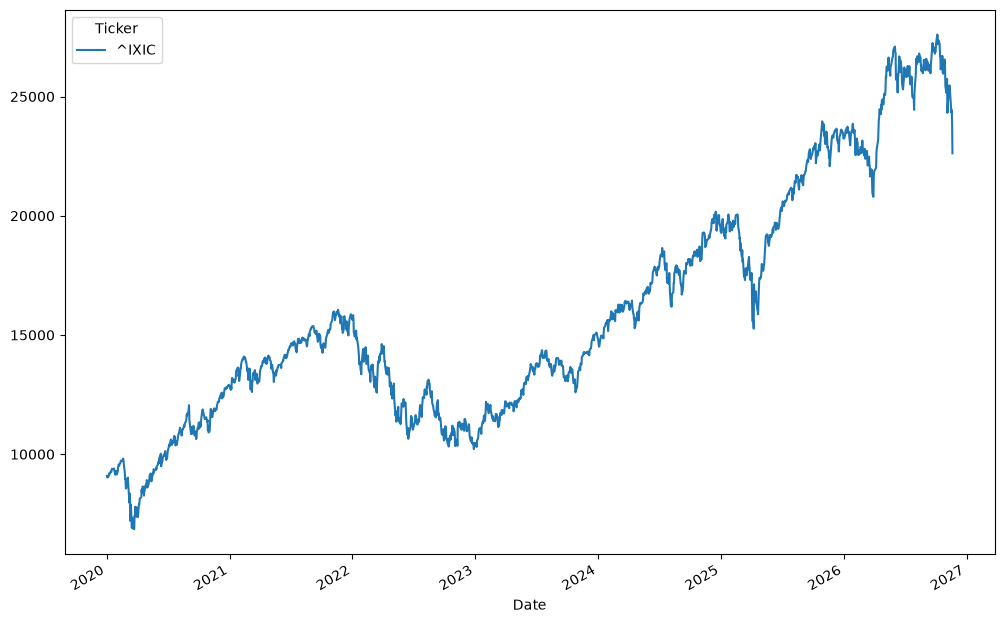

In [16]:
ticker = '^IXIC' #TICKER DEL NASDAQ
df = yf.download(ticker, '2020-01-01')
df.head()
df.Close.plot(figsize=(12,8))

In [17]:
scaler = StandardScaler()

df['Close'] = scaler.fit_transform(df['Close'])   # Limpiamos la data, solo nos quedamos con la columna de cierre y la escalamos para que tenga media 0 y desviación estándar 1

In [18]:
seq_length = 30 #Los dias que vamos a coger para predecir el siguiente dia

data = []

for i in range(len(df) - seq_length):
    data.append(df.Close[i:i+seq_length])
    
data = np.array(data)

In [19]:
train_size = int(len(data) * 0.8)

X_train = torch.from_numpy(data[:train_size, :-1, :]).float().to(device)
y_train = torch.from_numpy(data[:train_size, -1, :]).float().to(device)

X_test = torch.from_numpy(data[train_size:, :-1, :]).float().to(device)
y_test = torch.from_numpy(data[train_size:, -1, :]).float().to(device)

In [20]:
class PredictionModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(PredictionModel, self).__init__()
        
        self.num_layers = num_layers
        self.hidden_dim = hidden_dim
        
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])
        
        return out

In [21]:
model = PredictionModel(input_dim=1, hidden_dim=32, num_layers=2, output_dim=1).to(device)

In [22]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [23]:
num_epochs = 200

for i in range(num_epochs):
    y_train_pred = model(X_train)
    
    loss = criterion(y_train_pred, y_train)
    
    if i % 25 == 0:
        print(i, loss.item())
        
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

0 0.5625154972076416
25 0.017571143805980682
50 0.004409091081470251
75 0.003475429955869913
100 0.003206798108294606
125 0.0030309020075947046
150 0.002886351430788636
175 0.002762860618531704


In [24]:
model.eval()

y_test_pred = model(X_test)

y_train_pred = scaler.inverse_transform(y_train_pred.detach().cpu().numpy())
y_train = scaler.inverse_transform(y_train.detach().cpu().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().cpu().numpy())
y_test = scaler.inverse_transform(y_test.detach().cpu().numpy())


In [25]:
train_rmse = root_mean_squared_error(y_train[:, 0], y_train_pred[:, 0])
test_rmse = root_mean_squared_error(y_test[:, 0], y_test_pred[:, 0])

train_rmse, test_rmse



(254.575439453125, 1185.8466796875)

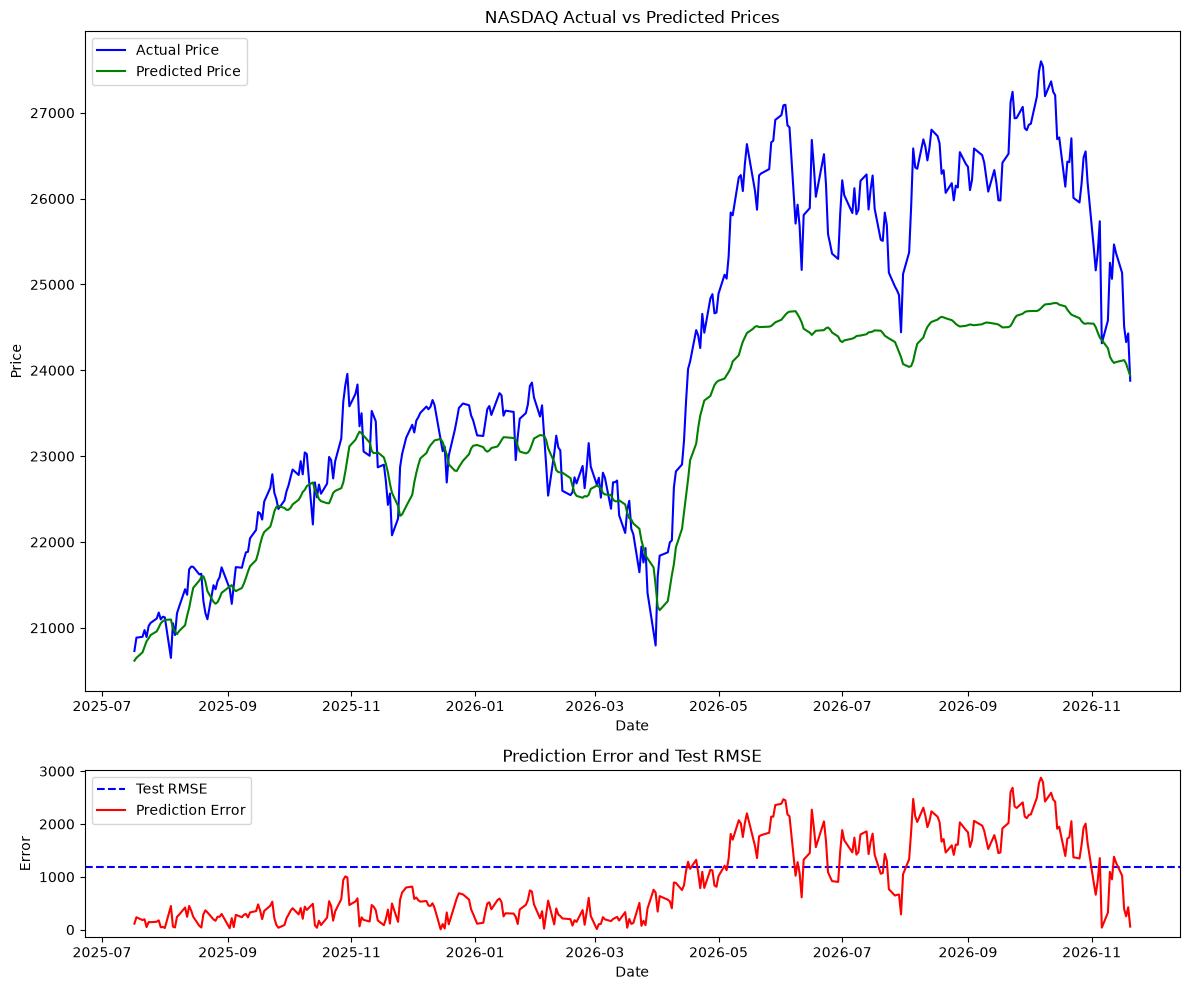

In [26]:
fig = plt.figure(figsize=(12, 10))

gs = fig.add_gridspec(4, 1)

ax1 = fig.add_subplot(gs[:3, 0])
ax1.plot(df.iloc[-len(y_test):].index, y_test, color='blue', label='Actual Price')
ax1.plot(df.iloc[-len(y_test):].index, y_test_pred[:, 0], color='green', label='Predicted Price')
ax1.legend()
plt.title('NASDAQ Actual vs Predicted Prices') 
plt.xlabel('Date')
plt.ylabel('Price')

ax2 = fig.add_subplot(gs[3, 0])
ax2.axhline(test_rmse, color='blue', linestyle='--', label='Test RMSE')
ax2.plot(df[-len(y_test):].index, abs(y_test - y_test_pred), 'r', label='Prediction Error')
ax2.legend()
plt.title('Prediction Error and Test RMSE')
plt.xlabel('Date')
plt.ylabel('Error')
plt.tight_layout()
plt.show()

In [28]:
import os
import joblib
import torch

# 1. Crear carpeta para mantener ordenados los archivos entrenados
os.makedirs("modelos", exist_ok=True)

# 2. Guardar únicamente los pesos aprendidos de la red neuronal
torch.save(model.state_dict(), "modelos/modelo_nasdaq.pt")

# 3. Guardar el escalador (StandardScaler) con la media y desviación exacta del entrenamiento
joblib.dump(scaler, "modelos/scaler_nasdaq.pkl")

print("Exportación completada: modelos/modelo_nasdaq.pt y modelos/scaler_nasdaq.pkl")

Exportación completada: modelos/modelo_nasdaq.pt y modelos/scaler_nasdaq.pkl
